In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
import warnings
warnings.filterwarnings('ignore')

In [56]:
df = pd.read_csv('DataCoSupplyChainDataset.csv', encoding='latin1')

In [57]:
df1 = df.copy()

In [58]:
df1.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [59]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  object 
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  object 
 9   Customer City                  180519 non-null  object 
 10  Customer Country               180519 non-null  object 
 11  Customer Email                 180519 non-null  object 
 12  Customer Fname                

In [60]:
df1['order date (DateOrders)'].unique()

array(['1/31/2018 22:56', '1/13/2018 12:27', '1/13/2018 12:06', ...,
       '1/21/2016 2:47', '1/20/2016 7:10', '1/17/2016 5:56'], dtype=object)

In [61]:
df1['shipping date (DateOrders)'].unique()

array(['2/3/2018 22:56', '1/18/2018 12:27', '1/17/2018 12:06', ...,
       '1/25/2016 2:47', '1/23/2016 7:10', '1/21/2016 5:56'], dtype=object)

#### - Convert the above two column's data type from string to datetime

In [62]:
df1.shape

(180519, 53)

In [63]:
df1.columns

Index(['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)',
       'Benefit per order', 'Sales per customer', 'Delivery Status',
       'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City',
       'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id',
       'Customer Lname', 'Customer Password', 'Customer Segment',
       'Customer State', 'Customer Street', 'Customer Zipcode',
       'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market',
       'Order City', 'Order Country', 'Order Customer Id',
       'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id',
       'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id',
       'Order Item Product Price', 'Order Item Profit Ratio',
       'Order Item Quantity', 'Sales', 'Order Item Total',
       'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status',
       'Order Zipcode', 'Product Card Id', 'Product Category Id',
       'Product De

In [64]:
df['Order Zipcode'].unique()

array([   nan, 99301., 90049., 94110., 66212., 77041., 85234., 95123.,
       93727., 85345., 45231., 47201., 19134., 60016., 60126., 98103.,
       94601., 10009., 28110., 80219., 90008., 77095., 32216., 77036.,
       74133., 94109., 92553., 20735., 60543., 60174., 31907., 62521.,
       92627., 28806., 35630.,  1852., 10024., 44312., 22153., 89015.,
       90045., 10011., 49505., 78664., 76017., 92105., 85705., 90032.,
       48227., 55407., 28205., 23602., 94122., 11572., 78207., 68104.,
       21215., 75081., 10035., 98115., 49201., 43229., 60653.,  6708.,
       98105., 19143., 42420., 80134., 94533., 92037., 90036., 22304.,
       35810., 19711., 38109., 72701., 23223., 40475., 65807., 33801.,
       13021., 45503., 78577., 11550., 40214., 67212., 76106., 21044.,
       30318., 79762., 60610., 75217., 90004., 89115., 95037., 97206.,
       14215., 79109., 33614., 75034., 28540., 32303.,  4240., 34952.,
       63116., 77070.,  1841., 97756., 19140., 28314., 13440., 60623.,
      

In [65]:
df['Customer Email'].nunique()

1

In [66]:
df['Customer Password'].nunique()

1

In [67]:
df1.replace(['?','-','',' ','empty','#','NaN','nan'],np.nan, inplace=True)

In [68]:
for i in df1.columns:
    if df1[i].isnull().sum() > 0:
        print(f"{i}: {df1[i].isnull().sum()}")

Customer Lname: 8
Customer Zipcode: 3
Order Zipcode: 155679
Product Description: 180519


#### - `Product Description` has all the null values
#### - `Order Zipcode` has 155679 null values
#### - `Customer Zipcode` has 3 null values
#### - `Customer Lname` as 8 null values

In [69]:
df1.duplicated().sum()

np.int64(0)

#### - No duplicates are present in the data

### **Data Cleaning**

#### - Converting all column names into lowercase and replacing white spaces with underscores

In [70]:
df1.columns = df1.columns.str.lower().str.replace(' ','_')

In [71]:
df1.columns

Index(['type', 'days_for_shipping_(real)', 'days_for_shipment_(scheduled)',
       'benefit_per_order', 'sales_per_customer', 'delivery_status',
       'late_delivery_risk', 'category_id', 'category_name', 'customer_city',
       'customer_country', 'customer_email', 'customer_fname', 'customer_id',
       'customer_lname', 'customer_password', 'customer_segment',
       'customer_state', 'customer_street', 'customer_zipcode',
       'department_id', 'department_name', 'latitude', 'longitude', 'market',
       'order_city', 'order_country', 'order_customer_id',
       'order_date_(dateorders)', 'order_id', 'order_item_cardprod_id',
       'order_item_discount', 'order_item_discount_rate', 'order_item_id',
       'order_item_product_price', 'order_item_profit_ratio',
       'order_item_quantity', 'sales', 'order_item_total',
       'order_profit_per_order', 'order_region', 'order_state', 'order_status',
       'order_zipcode', 'product_card_id', 'product_category_id',
       'product_de

#### - Changing columns to correct datatype

In [72]:
df1['order_date_(dateorders)'] = pd.to_datetime(df1['order_date_(dateorders)'], errors='coerce')

In [73]:
df1['shipping_date_(dateorders)'] = pd.to_datetime(df1['shipping_date_(dateorders)'], errors='coerce')

#### - Dropping unncessary columns

In [74]:
df1.drop([
    'product_description',
    'product_image',
    'order_zipcode',
    'customer_email',
    'customer_password'],inplace=True, axis=1)

In [75]:
df1['order_id'].nunique()

65752

In [76]:
numeric = df1.select_dtypes(include='number').columns

In [77]:
for i in numeric:
    if (df1[i] < 0).sum():
        print(f"{i}: {(df1[i] < 0).sum()}")

benefit_per_order: 33784
latitude: 9
longitude: 180414
order_item_profit_ratio: 33784
order_profit_per_order: 33784


In [78]:
(df1['benefit_per_order'] == df1['order_item_profit_ratio']).all()

np.False_

In [79]:
(df1['benefit_per_order'] == df1['order_profit_per_order']).all()

np.True_

In [80]:
df1.drop('benefit_per_order', axis=1, inplace=True)

### **Feature Engineering**

In [81]:
df1['order_date'] = pd.to_datetime(df1['order_date_(dateorders)'])

In [82]:
df1['shipping_date'] = pd.to_datetime(df1['shipping_date_(dateorders)'])

In [83]:
df1['order_year'] = df1['order_date'].dt.year

In [84]:
df1['order_month'] = df1['order_date'].dt.month

In [85]:
df1['order_day_of_week'] = df1['order_date'].dt.day_name()

In [86]:
df1['shipping_delay'] = df1['days_for_shipping_(real)'] - df1['days_for_shipment_(scheduled)']

In [87]:
df1['late_shipment'] = df1['shipping_delay'] > 0

In [88]:
df1['profit_margin'] = df1['order_profit_per_order'] / df1['sales']

In [89]:
df1['is_loss'] = df1['order_profit_per_order'] < 0

In [90]:
df1[['order_year','order_month','shipping_delay','late_shipment','profit_margin','is_loss']].head()

,order_year,order_month,shipping_delay,late_shipment,profit_margin,is_loss
0,2018,1,-1,False,0.278413,False
1,2018,1,1,True,-0.760000,True
2,2018,1,0,False,-0.756003,True
3,2018,1,-1,False,0.069748,False
4,2018,1,-2,False,0.409489,False


### **Exploratory Data Analysis**

In [91]:
df1['late_shipment'].mean() * 100
df1['is_loss'].mean() * 100
df1[['sales', 'order_profit_per_order']].describe()

,sales,order_profit_per_order
count,180519.000000,180519.000000
mean,203.772096,21.974989
std,132.273077,104.433526
min,9.990000,-4274.979980
25%,119.980003,7.000000
50%,199.919998,31.520000
75%,299.950012,64.800003
max,1999.989990,911.799988


#### Late delivery by shipping mode, region and market

In [92]:
df1.groupby('shipping_mode')['late_shipment'].mean().sort_values(ascending=False) * 100
df1.groupby('order_region')['late_shipment'].mean().sort_values(ascending=False) * 100
df1.groupby('market')['late_shipment'].mean().sort_values(ascending=False) * 100

market
Europe          57.687256
Pacific Asia    57.317014
USCA            57.149502
LATAM           57.022134
Africa          56.810746
Name: late_shipment, dtype: float64

#### Category profitability

#### Customer segment and department

In [93]:
df1.groupby('customer_segment')[['sales', 'order_profit_per_order']].sum()
df1.groupby('department_name')[['sales', 'order_profit_per_order']].sum().sort_values('order_profit_per_order', ascending=False)

,sales,order_profit_per_order
department_name,,
Fan Shop,1.711387e+07,1.834155e+06
Apparel,7.976255e+06,8.818829e+05
Golf,4.609028e+06,4.975236e+05
Footwear,4.006499e+06,4.102225e+05
Outdoors,1.253351e+06,1.452515e+05
Technology,1.039599e+06,1.131700e+05
Fitness,3.970509e+05,4.653806e+04
Discs Shop,2.288877e+05,2.419312e+04
Health and Beauty,1.060805e+05,9.493630e+03


#### Category profitability

In [94]:
cat = df1.groupby('category_name').agg(
    sales=('sales', 'sum'),
    profit=('order_profit_per_order', 'sum'),
    loss_rate=('is_loss', 'mean')
).sort_values('profit', ascending=False)

cat.head(10)
cat.tail(10)

,sales,profit,loss_rate
category_name,,,
Video Games,33310.500000,2717.519997,0.215990
Men's Clothing,43856.801269,2006.039969,0.240385
Basketball,27099.329343,1845.670003,0.164179
Golf Bags & Carts,10369.390336,1810.069992,0.098361
Baby,12229.560379,1525.029992,0.164251
Toys,6104.659979,900.710000,0.155009
Books,12587.399968,883.010008,0.192593
As Seen on TV!,20597.939964,714.429980,0.205882
CDs,3059.589989,383.850000,0.132841


#### Trend over time

In [95]:
monthly = df1.groupby(['order_year', 'order_month']).agg(
    sales=('sales', 'sum'),
    profit=('order_profit_per_order', 'sum'),
    late_rate=('late_shipment', 'mean')
).reset_index()

monthly.head(12)

,order_year,order_month,sales,profit,late_rate
0,2015,1,1.051590e+06,111660.740132,0.559376
1,2015,2,9.270099e+05,99140.660196,0.579192
2,2015,3,1.051254e+06,113778.210191,0.572175
3,2015,4,1.014463e+06,108083.679957,0.564378
4,2015,5,1.050478e+06,112147.900143,0.580735
5,2015,6,1.024006e+06,110147.160313,0.562719
6,2015,7,1.038081e+06,115624.059879,0.575958
7,2015,8,1.029495e+06,117979.770302,0.581453
8,2015,9,1.018339e+06,113467.940118,0.588521
9,2015,10,1.049154e+06,101757.870040,0.571105


#### Payment type and order status

In [96]:
df1['type'].value_counts(normalize=True) * 100
df1['order_status'].value_counts(normalize=True) * 100

order_status
COMPLETE           32.955534
PENDING_PAYMENT    22.065267
PROCESSING         12.132795
PENDING            11.204915
CLOSED             10.866446
ON_HOLD             5.431007
SUSPECTED_FRAUD     2.250179
CANCELED            2.045214
PAYMENT_REVIEW      1.048643
Name: proportion, dtype: float64

#### Charts


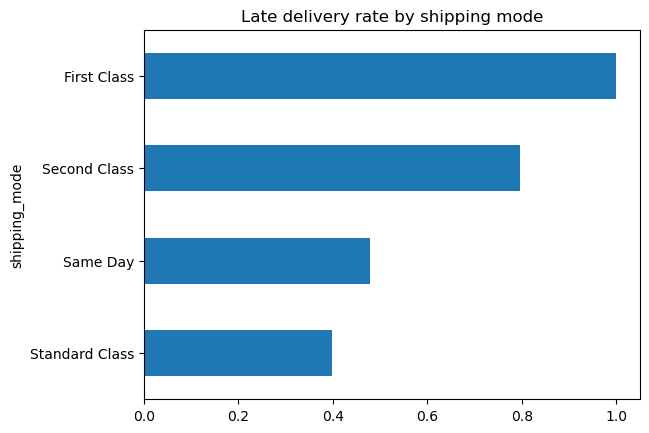

In [97]:
df1.groupby('shipping_mode')['late_shipment'].mean().sort_values().plot(kind='barh')
plt.title('Late delivery rate by shipping mode')
plt.show()


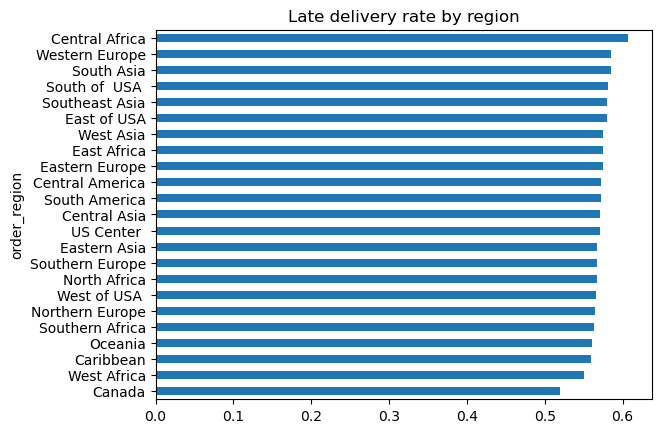

In [98]:
df1.groupby('order_region')['late_shipment'].mean().sort_values().plot(kind='barh')
plt.title('Late delivery rate by region')
plt.show()

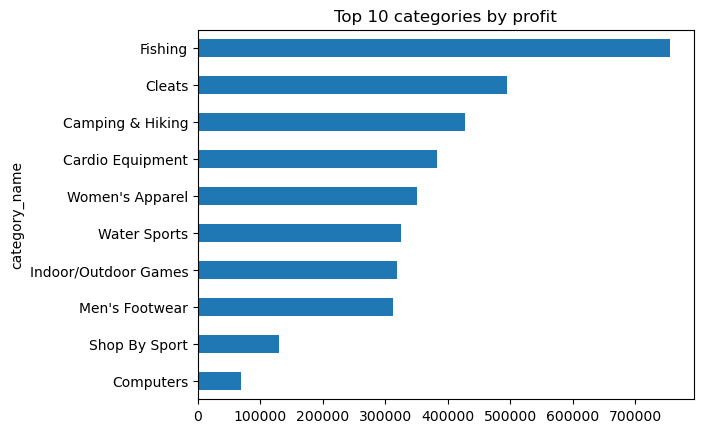

In [99]:
cat['profit'].sort_values().tail(10).plot(kind='barh')
plt.title('Top 10 categories by profit')
plt.show()

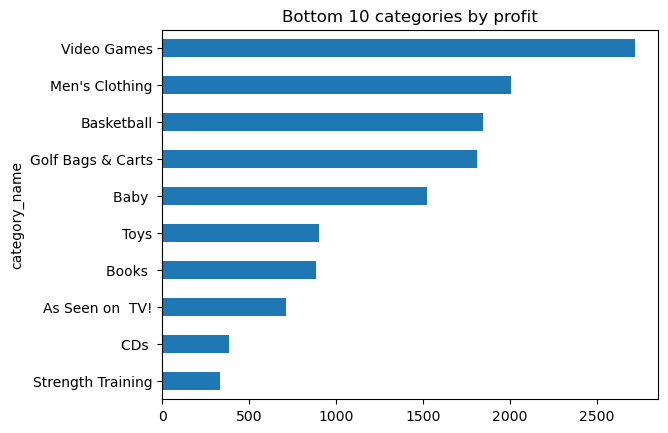

In [100]:
cat['profit'].sort_values().head(10).plot(kind='barh')
plt.title('Bottom 10 categories by profit')
plt.show()

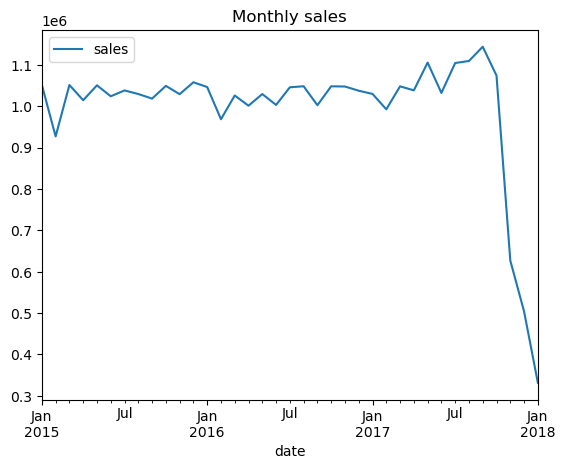

In [101]:
monthly['date'] = pd.to_datetime(monthly['order_year'].astype(str) + '-' + monthly['order_month'].astype(str) + '-01')
monthly.plot(x='date', y='sales')
plt.title('Monthly sales')
plt.show()

In [102]:
df1 = df1.drop(columns=['order_date_(dateorders)', 'shipping_date_(dateorders)'])
df1.columns = df1.columns.str.replace('(', '', regex=False).str.replace(')', '', regex=False)

In [ ]:
from sqlalchemy import create_engine

from sqlalchemy import create_engine
from sqlalchemy.engine import URL

url = URL.create(
    drivername='mysql+pymysql',
    username='root',
    password='password',
    host='localhost',
    port=3306,
    database='dataco'
)

engine = create_engine(url)

In [104]:
from sqlalchemy import text

with engine.connect() as conn:
    print(conn.execute(text('SELECT 1')).fetchone())

(1,)


In [105]:
df1.to_sql('staging_orders', engine, if_exists='replace', index=False, chunksize=10000)

180519